# Sketch-to-Image: SDXL-Lightning vs full SDXL + ControlNet

## 1. Check the GPU

In [1]:
!nvidia-smi --query-gpu=name,memory.total --format=csv

name, memory.total [MiB]
Tesla T4, 15360 MiB


## 2. Get the code


In [3]:
!unzip -qo sketch2image.zip -d /content && echo unzipped
%cd /content/sketch2image

unzipped
/content/sketch2image


### 2b. Keep results on Google Drive.

In [4]:
from google.colab import drive
drive.mount('/content/drive')
!mkdir -p /content/drive/MyDrive/sketch2image_outputs
!rm -rf outputs && ln -s /content/drive/MyDrive/sketch2image_outputs outputs && ls -la outputs

Mounted at /content/drive
lrwxrwxrwx 1 root root 43 Nov 19 23:47 outputs -> /content/drive/MyDrive/sketch2image_outputs


## 3. Install

In [5]:
!pip install -q -U diffusers transformers accelerate peft safetensors huggingface_hub gradio
!pip install -q opencv-python-headless scikit-image pandas matplotlib pyyaml

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
datasets 4.8.5 requires huggingface-hub<2.0,>=0.25.0, but you have huggingface-hub 2.4.0 which is incompatible.


## 4. Upload your sketches (.jpg or .png). Run the cell and pick your files.

In [6]:
from google.colab import files
import os, shutil
os.makedirs('sketches', exist_ok=True)
for name in files.upload():
    shutil.move(name, f'sketches/{name}')
print(sorted(os.listdir('sketches')))

Saving image1.png to image1.png
Saving image2.png to image2.png
Saving image3.png to image3.png
Saving image4.png to image4.png
['.gitkeep', 'image1.png', 'image2.png', 'image3.png', 'image4.png']


## 5. Describe each sketch


In [13]:
SUBJECTS = {
    'image1': 'a modern eco-friendly glass tower with curved balconies full of plants on every floor, a large sweeping arch rising across the facade, a glass skybridge connecting to a smaller glass pavilion, trees around the base',
    'image2': 'an underwater research station on the seabed, three transparent glass domes on metal legs connected by tube corridors, a laboratory with a microscope and computers inside, fish, a sea turtle, bubbles and seaweed around',
    'image3': 'a modern MRI scanner in a hospital room, large white ring-shaped gantry with a circular bore, a patient table sliding into it, a monitor on an articulated arm showing a brain scan and a waveform',
    'image4': 'a classic retro motorcycle in side view, round headlight, teardrop fuel tank, flat leather seat, chrome exhaust pipe, finned engine, spoked wheels, parked on a street',
}

import yaml
cfg = yaml.safe_load(open('configs/experiments.yaml'))
assert all(len(v.strip()) > 4 and v.strip() != 'a ...' for v in SUBJECTS.values()), 'Describe every sketch first!'
cfg['sketches'] = SUBJECTS
yaml.safe_dump(cfg, open('configs/experiments.yaml', 'w'), sort_keys=False)
print(yaml.safe_dump(cfg['sketches'], sort_keys=False))

image1: a modern eco-friendly glass tower with curved balconies full of plants on
  every floor, a large sweeping arch rising across the facade, a glass skybridge connecting
  to a smaller glass pavilion, trees around the base
image2: an underwater research station on the seabed, three transparent glass domes
  on metal legs connected by tube corridors, a laboratory with a microscope and computers
  inside, fish, a sea turtle, bubbles and seaweed around
image3: a modern MRI scanner in a hospital room, large white ring-shaped gantry with
  a circular bore, a patient table sliding into it, a monitor on an articulated arm
  showing a brain scan and a waveform
image4: a classic retro motorcycle in side view, round headlight, teardrop fuel tank,
  flat leather seat, chrome exhaust pipe, finned engine, spoked wheels, parked on
  a street



## 6. Check the sketch clean-up


[prep] image1: (1024, 720), stroke density 0.266
[prep] image2: (1024, 704), stroke density 0.241
[prep] image3: (1024, 760), stroke density 0.185
[prep] image4: (1024, 704), stroke density 0.198
Preprocessing done -> outputs/conditions and outputs/report/fig1_preprocessing.png


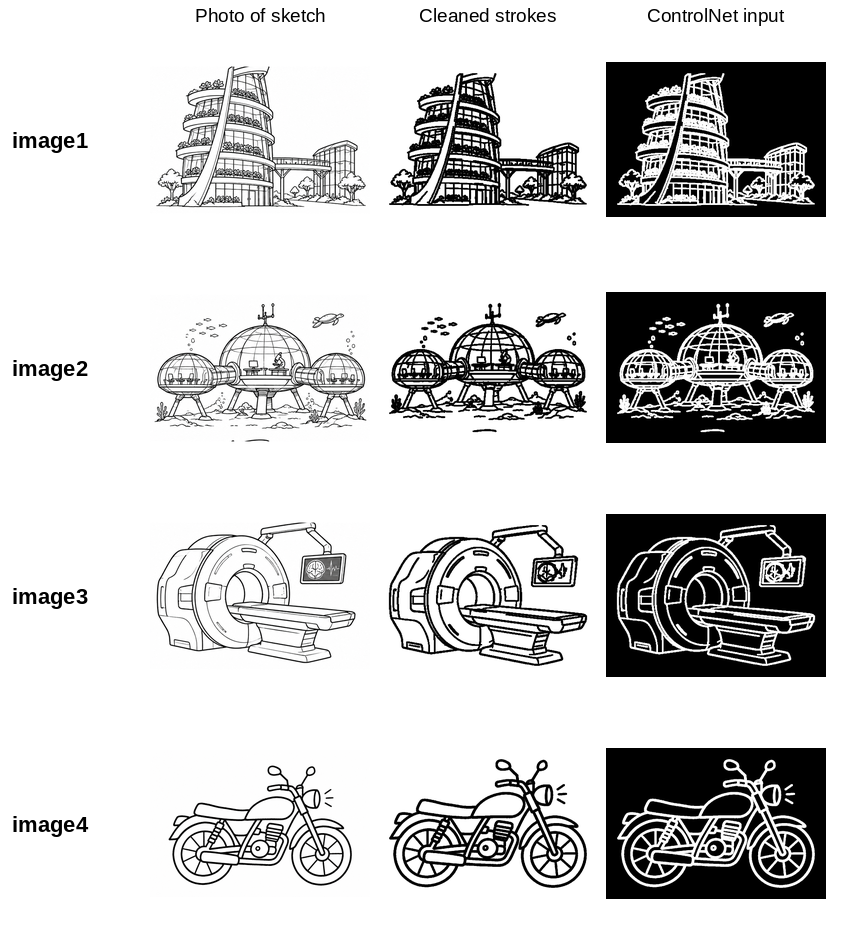

In [14]:
!python run_experiments.py --preprocess-only
from IPython.display import Image, display
display(Image('outputs/conditions/all_preprocessing.png', width=700))

## 7. Run
Progress and time left are printed for every image.

In [15]:
!sed -i 's/self.cn_pipe.enable_vae_tiling()/self.cn_pipe.vae.enable_tiling()/' sketch2image/pipeline.py
!grep -n "enable_tiling" sketch2image/pipeline.py

99:        self.cn_pipe.vae.enable_tiling()     # keeps the 1024 px decode inside T4 memory


In [16]:
!python run_experiments.py

[prep] image1: (1024, 720), stroke density 0.266
[prep] image2: (1024, 704), stroke density 0.241
[prep] image3: (1024, 760), stroke density 0.185
[prep] image4: (1024, 704), stroke density 0.198
88 unique images, 0 already done, 88 to generate
Loading models (first run downloads ~10 GB, takes a few minutes)...
Disabling torchao because diffusers requires `torchao>=0.15.0` but found version 0.10.0. Upgrade it with `pip install -U 'torchao>=0.15.0'`.
/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_validators.py:205: UserWarning: The `local_dir_use_symlinks` argument is deprecated and ignored in `hf_hub_download`. Downloading to a local directory does not use symlinks anymore.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)
Loading pipeline compone

## 8. Results

outputs/report/fig1_preprocessing.png


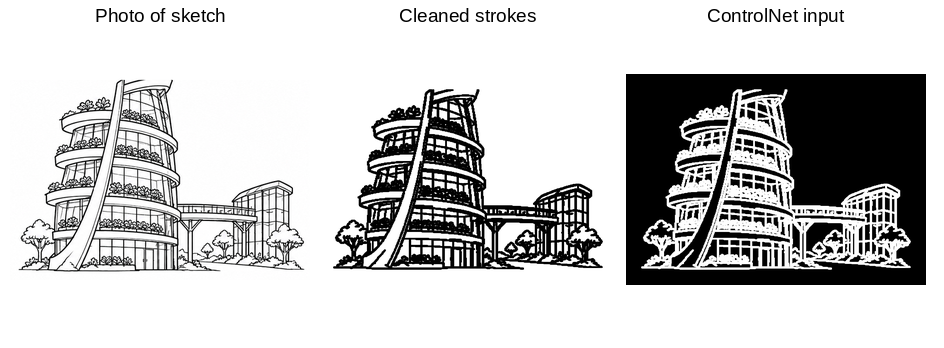

outputs/report/fig2_main_grid.png


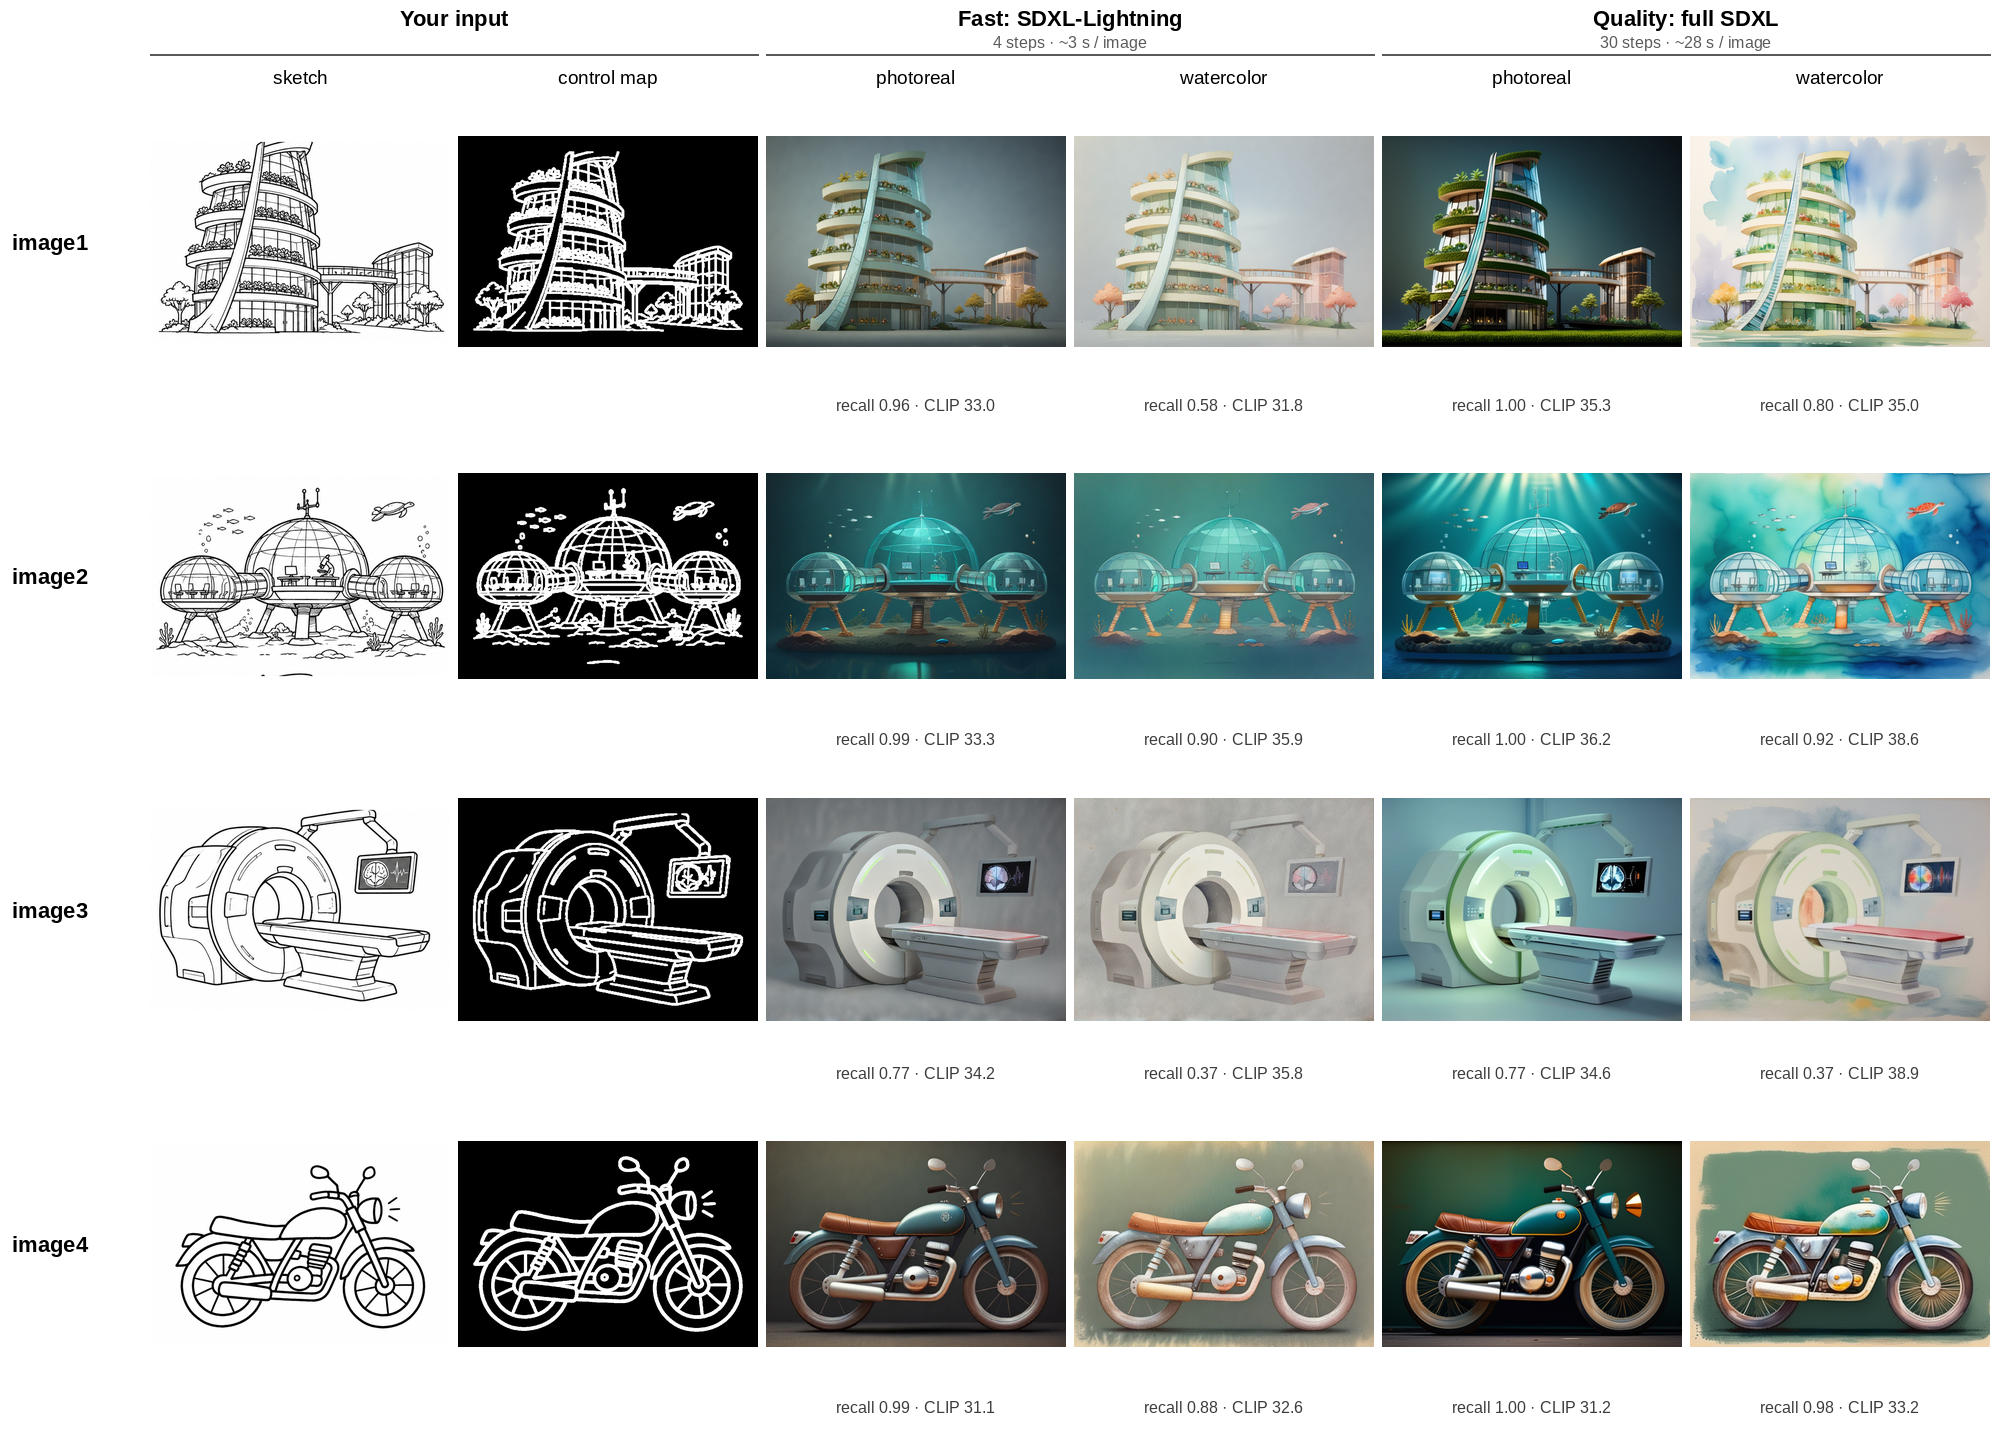

outputs/report/fig3_overconditioning.png


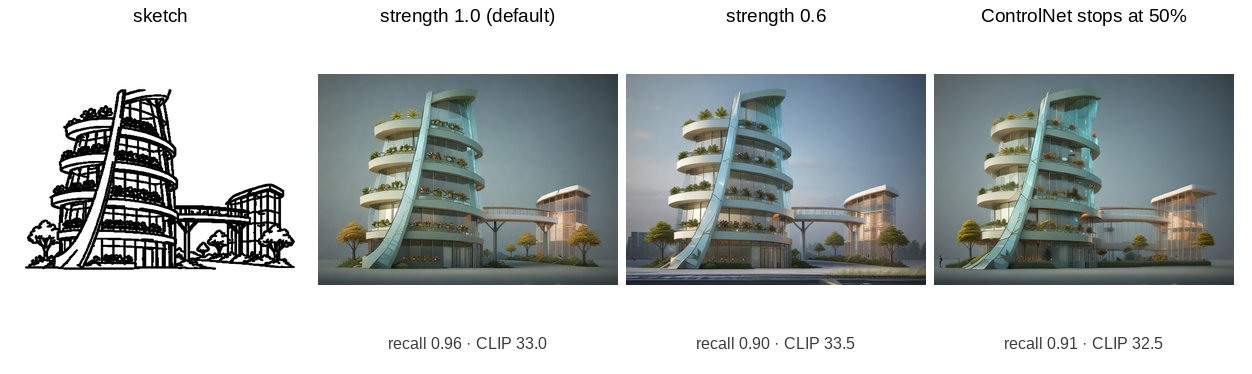

outputs/report/fig4_baselines.png


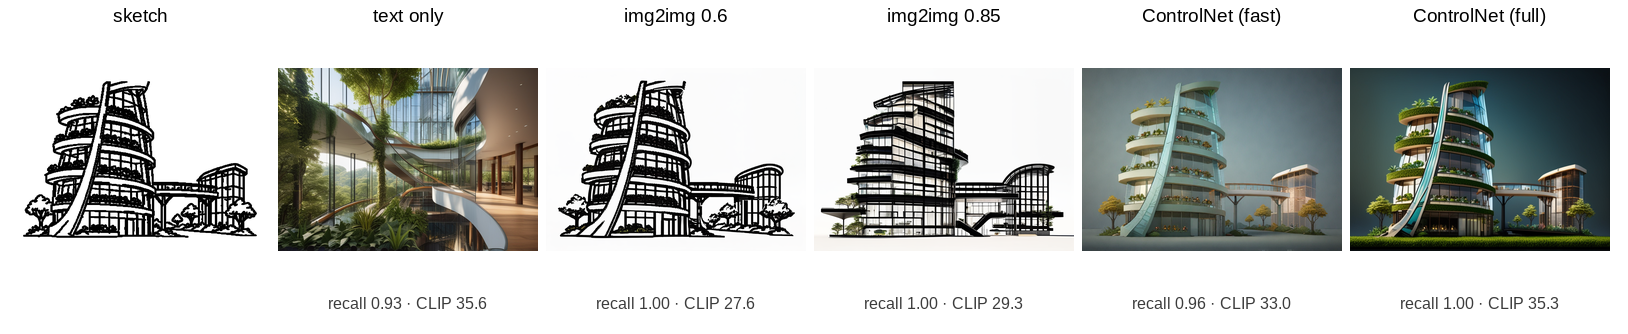

outputs/report/fig5_strength_sweep.png


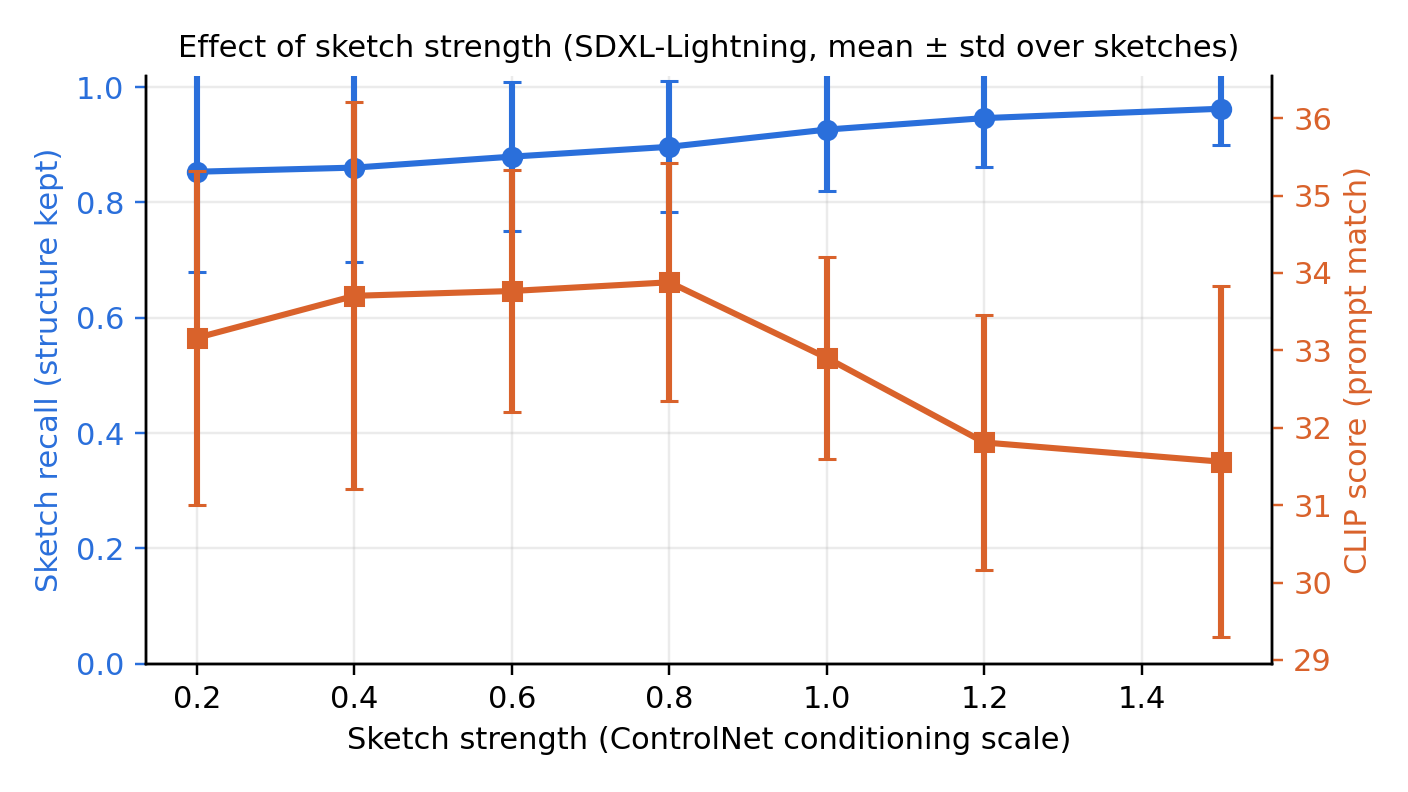

# Tables (mean ± std over 4 sketches)

## Table 1. Fast vs full model

| Model | Steps | s / image (median) | Sketch recall ↑ | Chamfer (px) ↓ | CLIP score ↑ |
|---|---|---|---|---|---|
| SDXL-Lightning | 2 | 2.0 | 0.909 ± 0.106 | 6.7 ± 6.3 | 32.5 ± 1.8 |
| SDXL-Lightning | 4 | 3.3 | 0.926 ± 0.106 | 5.5 ± 5.7 | 32.9 ± 1.3 |
| SDXL-Lightning | 8 | 5.9 | 0.905 ± 0.123 | 7.6 ± 8.0 | 33.6 ± 1.7 |
| Full SDXL | 30 | 28.0 | 0.942 ± 0.112 | 4.4 ± 5.9 | 34.3 ± 2.2 |

## Table 2. Style following (CLIP) and sketch preservation (recall) per style

| Style | Lightning CLIP ↑ | Full SDXL CLIP ↑ | Lightning recall ↑ | Full SDXL recall ↑ |
|---|---|---|---|---|
| photoreal | 32.9 ± 1.3 | 34.3 ± 2.2 | 0.926 ± 0.106 | 0.942 ± 0.112 |
| watercolor | 34.0 ± 2.1 | 36.4 ± 2.8 | 0.683 ± 0.253 | 0.769 ± 0.274 |
| concept_art | 35.1 ± 1.0 | 35.9 ± 1.7 | 0.938 ± 0.080 | 0.969 ± 0.051 |
| render3d | 34.4 ± 0.7 | 34.7 ± 2.5 | 0.871 ± 0.149 | 0.920 ± 0.149 |

## Table 3. Does the sketch matter? Baselines vs Contr

In [17]:
import glob
for f in sorted(glob.glob('outputs/report/fig*.png')):
    print(f); display(Image(f, width=1000))
print(open('outputs/report/tables.md').read())
print(open('outputs/report/settings.md').read())

## 9. Download

In [18]:
!cd outputs && zip -qr /content/report_assets.zip report conditions all_results.csv log.jsonl images
files.download('/content/report_assets.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 10. Web app
Prints a public `gradio.live` link.

In [6]:
!python app.py --share

Disabling torchao because diffusers requires `torchao>=0.15.0` but found version 0.10.0. Upgrade it with `pip install -U 'torchao>=0.15.0'`.
/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_validators.py:205: UserWarning: The `local_dir_use_symlinks` argument is deprecated and ignored in `hf_hub_download`. Downloading to a local directory does not use symlinks anymore.
  warnings.warn(
config.json: 100% 631/631 [00:00<00:00, 2.85MB/s]

diffusion_pytorch_model.safetensors: downloading bytes:   0% 1.46M/335M [00:00<02:18, 2.41MB/s]
diffusion_pytorch_model.safetensors: downloading bytes:  16% 53.5M/335M [00:00<00:02, 98.1MB/s, 2.35MB/s  ]
diffusion_pytorch_model.safetensors: downloading bytes:  94% 316M/335M [00:01<00:00, 192MB/s, 27.7MB/s  ]
diffusion_pytorch_model.safetensors: reconstructing file:  76% 255M/335M [00:02<00:00, 127MB/s, 4.30MB/s  ]  
diffusion_pytorch_model.safetensors: downloading bytes: 100% 316M/316M [00:02<00:00, 129MB/s, 28.7MB/s  ]
diffusion_pytorch_mo